# 02 - Data Cleaning

**Goal:** fix the problems found in notebook 01 so the data is safe to model.

**Input:** `data/raw/housing.csv`  |  **Output:** `data/processed/housing_clean.csv`

### Tasks in this notebook
- [x] Fill missing `total_bedrooms` values with the median
- [x] Remove duplicates (if any)
- [x] Remove rows with capped prices
- [x] Remove extreme outliers using NumPy percentiles
- [x] Apply a log transformation to skewed columns with NumPy
- [x] Re-check for missing values and save the cleaned data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
IMAGE_DIR = Path('../images')
OUT_PATH = Path('../data/processed/housing_clean.csv')

df = pd.read_csv('../data/raw/housing.csv')
rows_start = len(df)
print('Starting rows:', rows_start)

Starting rows: 20640


## 1. Missing values
We fill the 207 missing `total_bedrooms` with the **median**. The median is safer than the mean because the column has big outliers.

In [ ]:
print('Missing before:', df['total_bedrooms'].isna().sum())
median_bedrooms = df['total_bedrooms'].median()
print('Median total_bedrooms:', median_bedrooms)

df['total_bedrooms'] = df['total_bedrooms'].fillna(median_bedrooms)
print('Missing after: ', df['total_bedrooms'].isna().sum())

Missing before: 207
Median total_bedrooms: 435.0
Missing after:  0


## 2. Duplicates

In [ ]:
dups = df.duplicated().sum()
df = df.drop_duplicates()
print(f'Removed {dups} duplicate rows. Rows now: {len(df)}')

Removed 0 duplicate rows. Rows now: 20640


## 3. Capped prices
Prices above $500,000 were all recorded as exactly 500,001. The model would learn from a fake value, so we remove these rows. (This is a judgement call; mention it in your README.)

In [ ]:
cap = df['median_house_value'].max()
mask_capped = df['median_house_value'] >= cap
print(f'Rows at the cap ({cap:,.0f}): {mask_capped.sum()}')
df = df[~mask_capped].copy()
print('Rows now:', len(df))

Rows at the cap (500,001): 965
Rows now: 19675


## 4. Extreme outliers (NumPy percentiles + boolean masking)
For the count-style columns we remove rows above the **99.9th percentile**. This only removes the most extreme handful of rows.

In [ ]:
outlier_cols = ['total_rooms', 'total_bedrooms', 'population', 'households']
keep = np.ones(len(df), dtype=bool)

for col in outlier_cols:
    limit = np.percentile(df[col].to_numpy(), 99.9)
    keep &= (df[col].to_numpy() <= limit)
    print(f'{col:15s} 99.9th percentile = {limit:,.0f}')

print(f'\nRows removed as outliers: {(~keep).sum()}')
df = df[keep].copy()
print('Rows now:', len(df))

total_rooms     99.9th percentile = 21,927
total_bedrooms  99.9th percentile = 4,147
population      99.9th percentile = 10,458
households      99.9th percentile = 3,759

Rows removed as outliers: 33
Rows now: 19642


## 5. Log transformation (NumPy)
Rooms, bedrooms, population, and households are right-skewed. `np.log1p(x)` computes `log(1 + x)`, which compresses the long tail. Models, especially linear ones, often work better on less skewed data.

We **keep the original columns** and add new `_log` columns, because notebook 03 needs the originals to compute ratios.

In [ ]:
skewed_cols = ['total_rooms', 'total_bedrooms', 'population', 'households']

skew_before = df[skewed_cols].skew()
for col in skewed_cols:
    df[col + '_log'] = np.log1p(df[col].to_numpy())
skew_after = df[[c + '_log' for c in skewed_cols]].skew()
skew_after.index = skewed_cols

pd.DataFrame({'skew_before': skew_before, 'skew_after_log': skew_after}).round(2)

,skew_before,skew_after_log
total_rooms,3.02,-1.12
total_bedrooms,2.64,-1.05
population,2.53,-1.11
households,2.56,-1.10


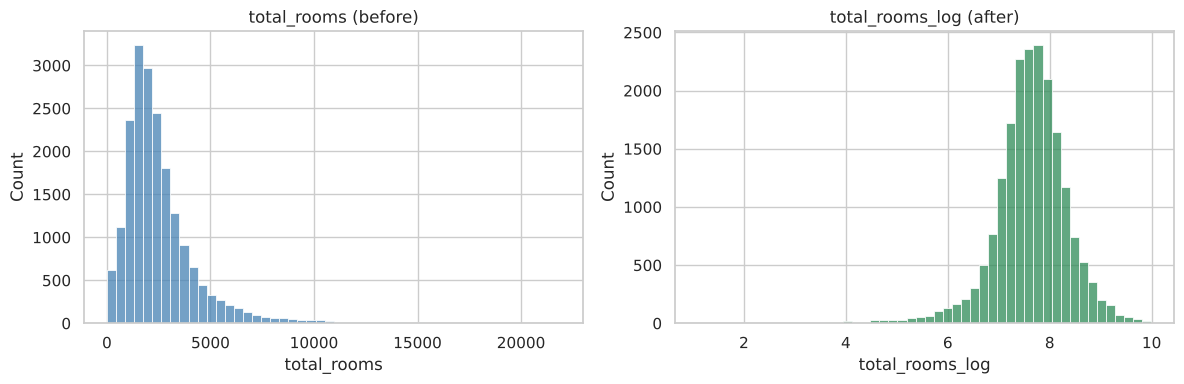

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['total_rooms'], bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('total_rooms (before)')
sns.histplot(df['total_rooms_log'], bins=50, ax=axes[1], color='seagreen')
axes[1].set_title('total_rooms_log (after)')
plt.tight_layout()
plt.savefig(IMAGE_DIR / '06_log_transform.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Final check and save

In [ ]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else 'None')
print(f'\nRows: {rows_start} -> {len(df)}  (removed {rows_start - len(df)})')

df.to_csv(OUT_PATH, index=False)
print('Saved to', OUT_PATH)
df.head()

Missing values per column:
None

Rows: 20640 -> 19642  (removed 998)


Saved to ../data/processed/housing_clean.csv


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,total_rooms_log,total_bedrooms_log,population_log,households_log
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.781058,4.867534,5.777652,4.844187
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,8.867850,7.009409,7.784057,7.037906
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,7.291656,5.252273,6.208590,5.181784
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,7.150701,5.463832,6.326149,5.393628
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,7.395108,5.638355,6.338594,5.560682


## 7. Check your work

In [ ]:
check = pd.read_csv(OUT_PATH)
assert check.isna().sum().sum() == 0, 'There are still missing values'
assert check.duplicated().sum() == 0, 'There are still duplicates'
assert check['median_house_value'].max() < 500001, 'Capped prices still present'
assert {'total_rooms_log', 'population_log'} <= set(check.columns), 'Log columns missing'
print(f'Notebook 02 checks passed ({len(check)} clean rows). Next: 03_feature_engineering.ipynb')

Notebook 02 checks passed (19642 clean rows). Next: 03_feature_engineering.ipynb
